# 02 — Difference-in-differences when treatment arrives in waves

**Question A:** does a county-level minimum wage increase reduce teen employment?

The estimand is `ATT(g, t)`. The outcome is in logs, so an estimate of `-0.04` is roughly a
4% reduction. Every number below is clustered by county.

In [1]:
from pathlib import Path
import sys

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
FIGS = REPO / "report" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 25)

from cid import io as cidio, viz
from IPython.display import display, Image


def show(name, width=780):
    """Display a figure the analysis just wrote, so output is deterministic across backends."""
    path = FIGS / name
    if path.exists():
        display(Image(filename=str(path), embed=True, width=width))
    else:
        print("missing figure:", path)

In [2]:
from cid.did import twfe, cs, sunabraham, diagnostics

mpdta = cidio.load_mpdta()
naive = twfe.static_twfe(mpdta)
print("naive two-way FE ATT  = %+.4f  (se %.4f)  95%% CI [%+.4f, %+.4f]"
      % (naive["estimate"], naive["std_error"], naive["ci_low"], naive["ci_high"]))

naive two-way FE ATT  = -0.0365  (se 0.0148)  95% CI [-0.0656, -0.0075]


## 1. The naive answer, and why it is the wrong object

A static two-way FE regression imposes one common, permanent, homogeneous effect. With three
cohorts of unequal size and dynamic effects (see the event study below, the effect *grows* with
exposure), the coefficient is a weighted average of pairwise 2x2 comparisons — including
comparisons in which the "control" county is already treated. Some of those weights are negative.
The estimate is not meaningless, but it is not `ATT(g,t)` either, and it cannot be interpreted
without knowing which comparisons produced it.

## 2. Dynamic specification: the parallel-trends test

Relative-period dummies, unit and time fixed effects, reference period `g - 1`, tails binned.
Coefficients left of the dashed line *should* be indistinguishable from zero — that is the
assumption, tested.

One design detail does all the work: never-treated counties stay in the sample, contributing to the
time effects while carrying no relative-period dummy. Drop them and the design loses rank — with
treated units only, `rel = year - cohort` is an exact linear combination of the time and unit
fixed effects, so the relative-period coefficients are not identified at all and a least-squares
solve will return anything from the solution set. They can look impressive and mean nothing.

In [3]:
tab, meta = twfe.event_study(mpdta, lo=-3, hi=3)
tab

,rel_time,coef,std_error,ci_low,ci_high,endpoints_binned
504,-3,0.016257,0.020611,-0.024141,0.056655,True
505,-2,0.022543,0.015026,-0.006908,0.051995,False
506,0,-0.018840,0.012230,-0.042812,0.005131,False
507,1,-0.045755,0.019851,-0.084664,-0.006846,False
508,2,-0.132912,0.032211,-0.196045,-0.069779,False
509,3,-0.093686,0.036101,-0.164444,-0.022928,True


In [4]:
print("joint test, all pre-treatment coefficients = 0:", {k: round(v, 4) for k, v in meta["pre_trend_joint"].items()})
print("joint test, all post-treatment coefficients = 0:", {k: round(v, 4) for k, v in meta["post_joint"].items()})
print("columns dropped for collinearity:", meta["dropped"] or "none")
print("units in design (309 of them never-treated):", meta["n_units"], "| rows:", meta["n_obs"])

joint test, all pre-treatment coefficients = 0: {'stat': 2.346, 'df': 2, 'p_value': 0.3094}
joint test, all post-treatment coefficients = 0: {'stat': 17.0563, 'df': 3, 'p_value': 0.0007}
columns dropped for collinearity: none
units in design (309 of them never-treated): 500 | rows: 2500


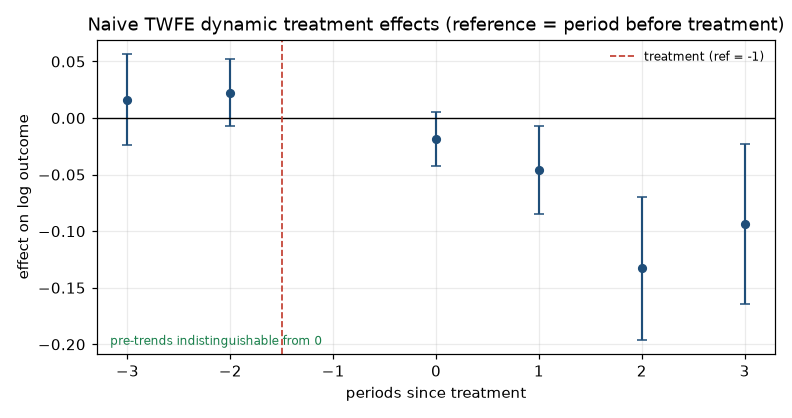

In [5]:
viz.event_study(tab, "Naive TWFE dynamic treatment effects (reference = period before treatment)",
                path=FIGS / "fig1_event_study.png")
show("fig1_event_study.png")

Pre-treatment coefficients are small and jointly insignificant (p above), so this data does not
*refute* parallel trends. That is the strongest statement available: the test can fail to reject,
it cannot confirm. Note the shape on the right of the line — the effect deepens with exposure,
from about -0.02 at `t = g` to -0.13 two periods later. An effect that grows over time is
precisely the condition under which static TWFE misweights pooled comparisons.

## 3. The contamination, made explicit

Every pairwise 2x2 difference-in-differences that a static estimator averages over, with pairs
flagged when the control cohort was *already treated* during its own pre-window. A biased control
is not a subtle problem: look at the sign flips.

In [6]:
pairs = diagnostics.forbidden_comparisons(mpdta)
pairs

,treated_cohort,control_cohort,pre_period,post_period,n_treated,n_control,did_2x2,control_already_treated_in_pre
0,2004,2006,2003,2004,20,40,-0.017023,False
1,2004,2007,2003,2004,20,131,-0.041010,False
2,2004,never,2003,2004,20,309,-0.010503,False
3,2006,2004,2005,2006,40,20,0.062241,True
4,2006,2007,2005,2006,40,131,0.026493,False
5,2006,never,2005,2006,40,309,-0.004595,False
6,2007,2004,2006,2007,131,20,-0.062502,True
7,2007,2006,2006,2007,131,40,0.010575,True
8,2007,never,2006,2007,131,309,-0.026054,False


In [7]:
bad = pairs[pairs.control_already_treated_in_pre]
print("contaminated pairs: %d of %d" % (len(bad), len(pairs)))
print(bad[["treated_cohort", "control_cohort", "pre_period", "post_period", "did_2x2"]].to_string(index=False))
print()
print("Clean pairs average      : %+.4f" % pairs[~pairs.control_already_treated_in_pre].did_2x2.mean())
print("Contaminated pairs average: %+.4f" % bad.did_2x2.mean())

contaminated pairs: 3 of 9
 treated_cohort control_cohort  pre_period  post_period   did_2x2
           2006           2004        2005         2006  0.062241
           2007           2004        2006         2007 -0.062502
           2007           2006        2006         2007  0.010575

Clean pairs average      : -0.0121
Contaminated pairs average: +0.0034


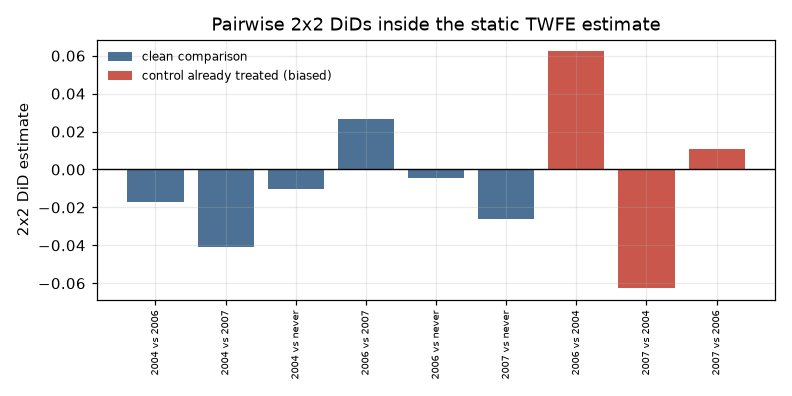

In [8]:
viz.pairwise_dids(pairs, "Pairwise 2x2 DiDs inside the static TWFE estimate", path=FIGS / "fig6_pairs.png")
show("fig6_pairs.png")

The 2006 cohort measured against the 2004 cohort returns **+0.062** — the opposite sign to the average of the
clean pairs (-0.012) — because the 2004 counties were already under treatment in 2005, so their
"pre-period" change contains the effect being subtracted. Averaging such pairs is what produces a
single TWFE number whose magnitude is defensible only by accident.

## 4. Callaway & Sant'Anna: estimate the estimand

Group-time ATT against not-yet-treated controls. All four reweighting strategies are run on the
same cells: if the design is sound, the estimator choice should not move the answer much.

In [9]:
surfaces = {}
for est in ["simple", "reg", "ipw", "dr"]:
    surfaces[est] = cs.att_surface(mpdta, covars=["lpop"], estimator=est,
                                   control="not-yet-treated", n_boot=200)
    overall = cs.aggregate(surfaces[est], "simple").iloc[0]
    print("%-7s overall ATT = %+.4f  (se %.4f, bootstrap CI [%+.4f, %+.4f])  cells=%d"
          % (est, overall.att, overall.se, overall.att - 1.96 * overall.se,
             overall.att + 1.96 * overall.se, overall.n_cells))

simple  overall ATT = -0.0398  (se 0.0098, bootstrap CI [-0.0591, -0.0205])  cells=7


reg     overall ATT = -0.0414  (se 0.0095, bootstrap CI [-0.0600, -0.0228])  cells=7


ipw     overall ATT = -0.0427  (se 0.0105, bootstrap CI [-0.0633, -0.0221])  cells=7


dr      overall ATT = -0.0413  (se 0.0096, bootstrap CI [-0.0601, -0.0226])  cells=7


In [10]:
dr = surfaces["dr"]
dr

,g,t,rel_time,n_treated,n_control,att,se,ci_low,ci_high,estimator,control_rule
0,2004.0,2004,0,20,480,-0.021066,0.023010,-0.062442,0.022923,dr,not-yet-treated
1,2004.0,2005,1,20,480,-0.081545,0.029708,-0.140893,-0.024056,dr,not-yet-treated
2,2004.0,2006,2,20,440,-0.137711,0.032711,-0.213986,-0.081293,dr,not-yet-treated
3,2004.0,2007,3,20,309,-0.106543,0.031033,-0.169279,-0.052820,dr,not-yet-treated
4,2006.0,2006,0,40,440,0.008363,0.018112,-0.025540,0.041249,dr,not-yet-treated
5,2006.0,2007,1,40,309,-0.041162,0.019069,-0.074185,-0.002920,dr,not-yet-treated
6,2007.0,2007,0,131,309,-0.028781,0.017517,-0.064731,0.002806,dr,not-yet-treated


Cell by cell, the pattern is consistent: effects are negative, near zero in the first year of
exposure, and larger for the 2004 cohort which has four post-periods. Note `n_control` shrinking
as `t` advances — 480 counties are available as not-yet-treated in 2004, only 309 (the never
treated) by 2007. Late cells are thinner, which is why the overall average should be reported with
its composition, not as a lone number.

In [11]:
pd.DataFrame({
    est: cs.aggregate(s, "event").set_index("label").att.round(4) for est, s in surfaces.items()
})

,simple,reg,ipw,dr
label,,,,
event time +0,-0.0189,-0.0200,-0.0194,-0.0202
event time +1,-0.0536,-0.0550,-0.0609,-0.0546
event time +2,-0.1363,-0.1385,-0.1388,-0.1377
event time +3,-0.1008,-0.1075,-0.1139,-0.1065


In [12]:
cs.aggregate(dr, "group")

,label,att,se,n_cells,n_treated
0,cohort 2004,-0.086716,0.014674,4,20
1,cohort 2006,-0.016399,0.013150,2,40
2,cohort 2007,-0.028781,0.017517,1,131


## 5. Sun-Abraham: the same estimand, a different weighting

Interaction-weighted estimator: never-treated units only as controls, cohort effects weighted by
each cohort's share of treated units at that event time. It is *more* restrictive in its control
set (309 counties rather than the not-yet-treated pool) and should be read as a robustness check
on the comparison-group rule, not as a competing answer.

In [13]:
cohort_tab = sunabraham.cohort_effects(mpdta, lo=-3, hi=3, n_boot=0)
iw = sunabraham.iw_event_time(cohort_tab)
iw

,rel_time,att,se,ci_low,ci_high,n_treated,cohorts
0,-3,0.025022,0.017849,-0.009962,0.060006,171,"[2006, 2007]"
1,-2,0.024459,0.014493,-0.003948,0.052865,171,"[2006, 2007]"
2,0,-0.019932,0.012311,-0.044061,0.004198,191,"[2004, 2006, 2007]"
3,1,-0.050957,0.017230,-0.084729,-0.017186,60,"[2004, 2006]"
4,2,-0.137259,0.037241,-0.210251,-0.064267,20,[2004]
5,3,-0.100811,0.035100,-0.169608,-0.032015,20,[2004]


In [14]:
print("Sun-Abraham overall (post cells, share-weighted):",
      {k: (round(v, 4) if isinstance(v, float) else v) for k, v in sunabraham.overall_iw(cohort_tab).items()})
print("Callaway-SantAnna overall (DR):", cs.aggregate(dr, "simple").att.iloc[0].round(4))
print("naive TWFE:", round(naive["estimate"], 4))

Sun-Abraham overall (post cells, share-weighted): {'estimate': -0.04, 'n_cells': 7, 'cohorts': [2004, 2006, 2007]}
Callaway-SantAnna overall (DR): -0.0413
naive TWFE: -0.0365


## 6. Pre-treatment placebo cells

The same machinery run on periods *before* treatment. These should be zero.

In [15]:
pre = diagnostics.pretrend_cells(mpdta, covars=["lpop"], estimator="dr", n_boot=100)
pre[["g", "t", "rel_time", "att", "se", "ci_low", "ci_high", "n_treated", "n_control"]]

,g,t,rel_time,att,se,ci_low,ci_high,n_treated,n_control
0,2006.0,2003,-3,0.008487,0.028207,-0.042321,0.069390,40,460
1,2006.0,2004,-2,0.003878,0.019514,-0.042159,0.037607,40,440
2,2007.0,2003,-4,-0.000865,0.024155,-0.033323,0.043092,131,369
3,2007.0,2004,-3,0.033384,0.021552,-0.010717,0.071780,131,349
4,2007.0,2005,-2,0.029183,0.018720,-0.008699,0.056079,131,349


In [16]:
z = (pre.att / pre.se).abs()
print("largest |t| among pre-treatment cells: %.2f (cell g=%d, t=%d)"
      % (z.max(), pre.loc[z.idxmax(), "g"], pre.loc[z.idxmax(), "t"]))
print("cells with 95%% CI excluding zero: %d of %d" % (int(((pre.ci_low > 0) | (pre.ci_high < 0)).sum()), len(pre)))

largest |t| among pre-treatment cells: 1.56 (cell g=2007, t=2005)
cells with 95% CI excluding zero: 0 of 5


## 7. What to report

| Estimator | Estimate | What it actually is |
|---|---|---|
| Static two-way FE | see cell 1 | A weighted mix of pairwise 2x2 DiDs, some contaminated, sign-flipped |
| Callaway-Sant'Anna (DR) | overall, and event-time path | `ATT(g,t)`, not-yet-treated controls, log points |
| Sun-Abraham | share-weighted event path | `ATT(g,t)`, never-treated controls only |
| Naive before/after | (not run) | Assumes nothing else changed — no design at all |

Interpretation for a non-statistician: minimum wage increases reduced teen employment by roughly
**3-4%** on average across the treated counties and their post-periods, the effect building over
about two years rather than appearing immediately — and the naive TWFE point estimate happens to
land near the robust one here *because* its errors partly cancel, which is not a property you can
rely on.

Next notebook: what to do when there is only one treated unit and none of this applies.